---
title: "Angular Momentum and Torque — Level 2"
short_title: "03 Angular Momentum"
numbering:
  heading_2: true
  equation: true
---

# Angular Momentum and Torque

:::{seealso} Math for this topic
- [M2: Coordinates, integrals and the delta function](../math/02-coordinates-integrals-delta.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 9–10 | Use L = r × p and torque for simple rotations |
| **2** | **Taylor, ch. 3** | **Treat central forces as 1D problems; use angular momentum conservation** |
| 3 | Goldstein, ch. 3 | Kepler problem via effective potential, Laplace–Runge–Lenz vector |

The new skill at this level: turning a 2D orbit problem into a 1D energy problem with an effective potential

Math for this topic: M2, coordinates, multiple integrals and the delta function.
:::

Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Angular Momentum of a Particle

For a particle at position $\vec{r}$ (measured from a chosen origin) with momentum $\vec{p}$,

$$
\vec{\ell} = \vec{r}\times\vec{p}, \qquad \vec{\Gamma} = \vec{r}\times\vec{F}, \qquad \dot{\vec{\ell}} = \vec{\Gamma} .
$$ (eq-torque)

The last equation follows from the product rule: $\dot{\vec{\ell}} = \dot{\vec{r}}\times\vec{p} + \vec{r}\times\dot{\vec{p}}$, and the first term is $\vec{v}\times m\vec{v} = \vec{0}$.

Both $\vec{\ell}$ and $\vec{\Gamma}$ depend on the choice of origin. Pick the origin to make the torque vanish when you can.

:::{prf:theorem} Central forces conserve angular momentum
:label: thm-central-L

If the force on a particle always points along $\vec{r}$ (toward or away from the origin), then $\vec{\ell}$ is constant. The motion then lies in the fixed plane through the origin perpendicular to $\vec{\ell}$.
:::

The planar motion is why orbit problems are two-dimensional, and the conserved magnitude $\ell = mr^2\dot\phi$ is the polar-coordinate result from the Newton's laws notes.

### Kepler's second law

In time $dt$ the position vector sweeps out a thin triangle of area $dA = \tfrac12 r^2\,d\phi$. So

$$
\frac{dA}{dt} = \frac12 r^2\dot\phi = \frac{\ell}{2m} = \text{constant}.
$$

Equal areas in equal times holds for **every** central force, not only gravity. It is angular momentum conservation in geometric form.

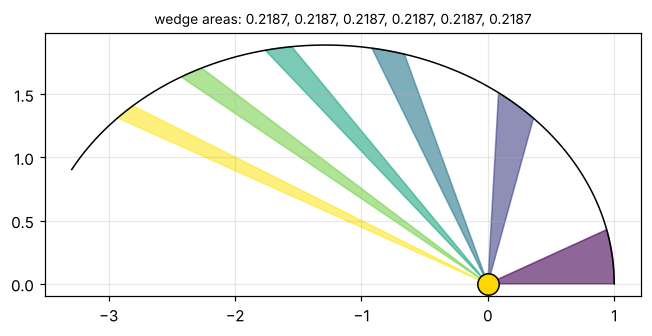

In [2]:
#| label: fig-equal-areas
#| caption: An elliptical orbit integrated numerically. The shaded wedges each span the same time interval; the planet moves fast near the focus and slowly far away, but every wedge has the same area.
GM = 1.0
def rhs(t, s):
    x, y, vx, vy = s
    r3 = (x * x + y * y)**1.5
    return [vx, vy, -GM * x / r3, -GM * y / r3]

sol = solve_ivp(rhs, (0, 8.2), [1.0, 0, 0, 1.25], dense_output=True, rtol=1e-10, atol=1e-12)
tt = np.linspace(0, 8.2, 3000)
x, y = sol.sol(tt)[:2]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, y, "k", lw=1)
ax.plot(0, 0, "o", color="gold", ms=14, mec="k")
areas = []
for k, c in enumerate(plt.cm.viridis(np.linspace(0, 1, 6))):
    ts = np.linspace(k * 1.3, k * 1.3 + 0.35, 60)
    xs, ys = sol.sol(ts)[:2]
    ax.fill(np.r_[0, xs], np.r_[0, ys], color=c, alpha=0.6)
    areas.append(0.5 * abs(np.sum(xs[:-1] * ys[1:] - xs[1:] * ys[:-1])))
ax.set_aspect("equal")
ax.set_title("wedge areas: " + ", ".join(f"{a:.4f}" for a in areas), fontsize=9)
plt.show()

## Systems of Particles

For many particles, the total angular momentum $\vec{L} = \sum_\alpha\vec{\ell}_\alpha$ obeys

$$
\dot{\vec{L}} = \vec{\Gamma}^{\text{ext}} ,
$$ (eq-system-torque)

**provided** each internal force pair acts along the line joining the two particles (the strong form of the third law). Then each pair contributes $(\vec{r}_\alpha - \vec{r}_\beta)\times\vec{F}_{\alpha\beta} = \vec{0}$.

It is often convenient to split the angular momentum the same way as the kinetic energy:

$$
\vec{L} = \vec{R}\times M\vec{V} + \vec{L}_{\text{cm}} ,
$$

the angular momentum of the center of mass plus the "spin" about the center of mass. The Earth's orbital and spin angular momenta are the classic example. Equation {eq}`eq-system-torque` also holds about the center of mass even when it accelerates, which is why we can analyze a spinning, falling object about its own center.

## Rotation About a Fixed Axis

For a rigid body rotating with angular velocity $\omega$ about a fixed $z$-axis, each mass element moves in a circle of radius $s$ (its distance from the axis) at speed $s\omega$. Adding up its angular momentum about the axis:

$$
L_z = \left(\int s^2\,dm\right)\omega = I\omega, \qquad \Gamma_z = I\dot\omega .
$$

The moment of inertia $I$ is computed with the multiple integrals of M2. Two shortcuts:

- **Parallel-axis theorem:** $I = I_{\text{cm}} + Md^2$ for an axis parallel to one through the center of mass, a distance $d$ away.
- **Perpendicular-axis theorem** (flat bodies only): $I_z = I_x + I_y$.

:::{warning} Only for a fixed axis (or a symmetry axis)
$L = I\omega$ with a scalar $I$ works when the rotation axis is fixed or is a symmetry axis of the body. In general $\vec{L}$ is **not parallel** to $\vec{\omega}$, and $I$ becomes a matrix (the inertia tensor). That is the rigid-body topic later in the ladder.
:::

### Exercises

1. A uniform rod of mass $M$ and length $\ell$ swings about one end. Find its moment of inertia and the frequency of small oscillations.
2. A skater spinning at 2 rev/s with arms out ($I = 4\ \text{kg m}^2$) pulls them in ($I = 1.6\ \text{kg m}^2$). Find the new spin rate and the ratio of kinetic energies. Where does the extra energy come from?

:::{dropdown} Hints
1. $I_{\text{cm}} = \tfrac1{12}M\ell^2$; use the parallel-axis theorem. The torque from gravity is $-Mg(\ell/2)\sin\phi$.
2. $L$ is conserved, and $T = L^2/2I$.
:::

:::{dropdown} Answers
1. $I = \tfrac13M\ell^2$ and $\omega = \sqrt{3g/2\ell}$, the same as a simple pendulum of length $\tfrac23\ell$.
2. 5 rev/s; $T_2/T_1 = I_1/I_2 = 2.5$. The skater does work pulling the arms inward against the centrifugal tendency.
:::

## Central Forces as One-Dimensional Problems

For a particle (or a two-body system, using the reduced mass $\mu$) in a central potential $U(r)$, both energy and angular momentum are conserved. In polar coordinates, $v^2 = \dot r^2 + r^2\dot\phi^2$, and $\dot\phi = \ell/(mr^2)$, so

$$
E = \tfrac12m\dot r^2 + \underbrace{\frac{\ell^2}{2mr^2} + U(r)}_{U_{\text{eff}}(r)} .
$$ (eq-ueff)

This is the energy equation of a particle moving in **one** dimension, $r$, in the **effective potential** $U_{\text{eff}}$. The extra term $\ell^2/(2mr^2)$, the **centrifugal barrier**, keeps a particle with angular momentum from reaching the origin.

Everything from 1D energy analysis now applies to the radial motion:

- **Turning points** $r_{\min}$, $r_{\max}$ are where $E = U_{\text{eff}}$. Between them the orbit is bounded.
- A **circular orbit** sits at a minimum of $U_{\text{eff}}$: $U_{\text{eff}}'(r_0) = 0$.
- It is **stable** if $U_{\text{eff}}''(r_0) > 0$, and small radial oscillations then have frequency $\omega_r = \sqrt{U_{\text{eff}}''(r_0)/m}$.

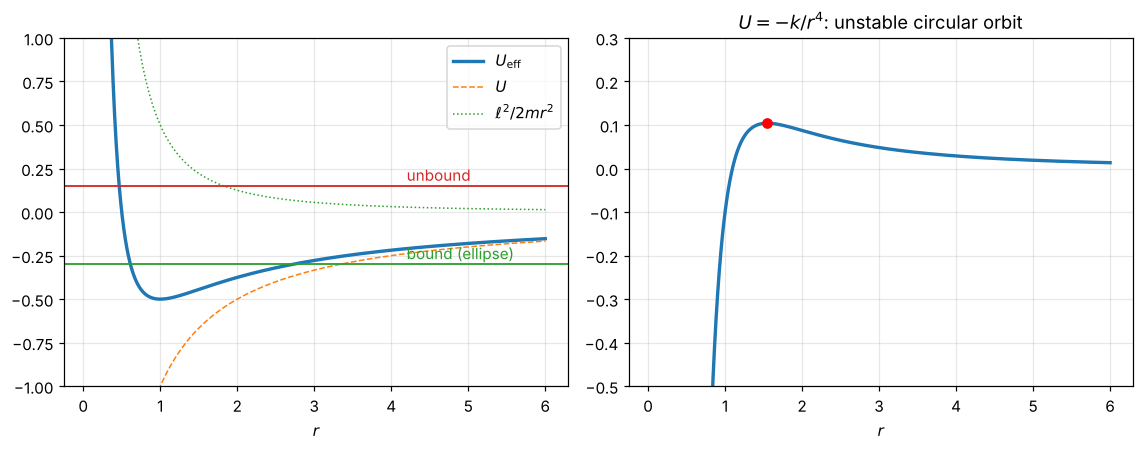

In [3]:
#| label: fig-ueff
#| caption: Effective potentials (m = ℓ = 1). Left, gravity, U = −k/r. The well gives bound orbits for E < 0, with turning points where an energy line meets the curve. Right, U = −k/r⁴, which falls faster than the barrier rises, so the circular orbit sits at a maximum and is unstable.
r = np.linspace(0.05, 6, 600)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
k = 1.0
Ue = 1 / (2 * r**2) - k / r
axes[0].plot(r, Ue, lw=2.2, label=r"$U_{\rm eff}$")
axes[0].plot(r, -k / r, "--", lw=1, label="$U$")
axes[0].plot(r, 1 / (2 * r**2), ":", lw=1, label=r"$\ell^2/2mr^2$")
for E, c in [(-0.3, "tab:green"), (0.15, "tab:red")]:
    axes[0].axhline(E, color=c, lw=1.2)
axes[0].text(4.2, -0.27, "bound (ellipse)", color="tab:green")
axes[0].text(4.2, 0.18, "unbound", color="tab:red")
axes[0].set_ylim(-1, 1); axes[0].set_xlabel("$r$"); axes[0].legend(loc="upper right")
k4 = 0.6
Ue4 = 1 / (2 * r**2) - k4 / r**4
axes[1].plot(r, Ue4, lw=2.2)
r0 = np.sqrt(4 * k4)
axes[1].plot(r0, 1 / (2 * r0**2) - k4 / r0**4, "ro")
axes[1].set_ylim(-0.5, 0.3); axes[1].set_xlabel("$r$")
axes[1].set_title(r"$U = -k/r^4$: unstable circular orbit")
plt.tight_layout(); plt.show()

### Which forces allow stable circular orbits?

For a power-law force $F(r) = -kr^n$ ($k>0$), a circular orbit at $r_0$ needs $\ell^2/(mr_0^3) = kr_0^n$. Using that to simplify $U_{\text{eff}}''(r_0)$ gives

$$
U_{\text{eff}}''(r_0) = (n + 3)\,\frac{\ell^2}{mr_0^4} .
$$

Circular orbits are stable only for $n > -3$. Comparing the radial frequency with the orbital frequency $\omega_\phi = \ell/(mr_0^2)$ gives $\omega_r = \sqrt{n+3}\,\omega_\phi$. So the angle swept between closest and farthest approach (the **apsidal angle**) of a nearly circular orbit is

$$
\Delta\phi = \frac{\pi}{\sqrt{n + 3}} .
$$ (eq-apsidal)

For gravity ($n = -2$), $\Delta\phi = \pi$, so the orbit closes after one trip around: an ellipse with the force center at a focus. For a spring ($n = 1$), $\Delta\phi = \pi/2$: an ellipse centered on the force center. For other powers, the orbit generally does not close and traces a rosette.

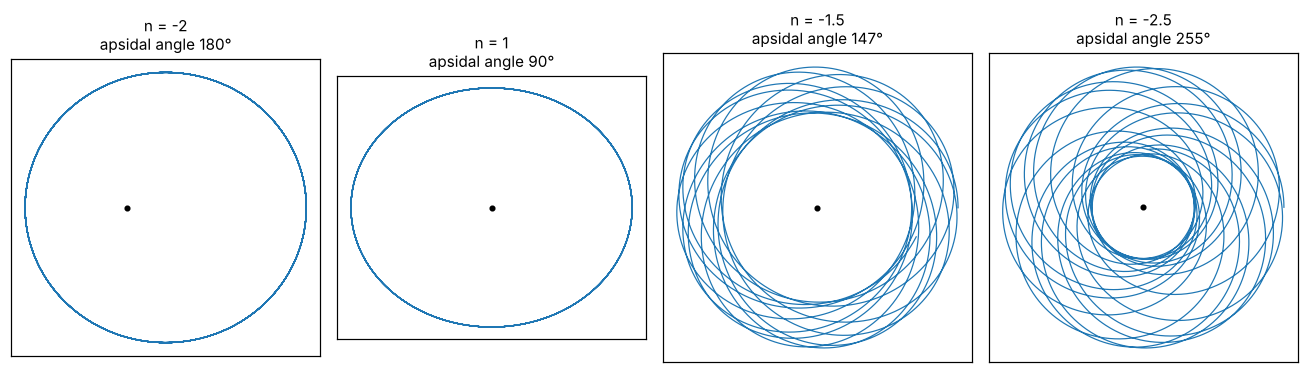

In [4]:
#| label: fig-rosettes
#| caption: Orbits under F = −r^n starting from the same kind of slightly non-circular initial conditions. Gravity (n = −2) and the spring (n = 1) give closed orbits; other powers precess into rosettes, with apsidal angles π/√(n+3).
def orbit(n, T):
    def rhs(t, s):
        x, y, vx, vy = s
        r = np.hypot(x, y)
        a = -r**n / r
        return [vx, vy, a * x, a * y]
    v0 = 0.85                      # circular speed at r = 1 is 1 for every n
    return solve_ivp(rhs, (0, T), [1, 0, 0, v0], max_step=0.01, rtol=1e-9)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, n in zip(axes, [-2, 1, -1.5, -2.5]):
    s = orbit(n, 60)
    ax.plot(s.y[0], s.y[1], lw=0.8)
    ax.plot(0, 0, "ko", ms=3)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"n = {n}\napsidal angle {180 / np.sqrt(n + 3):.0f}°", fontsize=10)
plt.tight_layout(); plt.show()

In [5]:
# The stability result, symbolically
r, l, m, k, n = sp.symbols("r ell m k n", positive=True)
Ueff_prime = -l**2 / (m * r**3) + k * r**n          # derivative of U_eff for F = -k r^n
Ueff_2 = sp.diff(Ueff_prime, r)
r0_rule = {k: l**2 / (m * r**(n + 3))}              # circular-orbit condition solved for k
print("U_eff''(r0) =", sp.simplify(Ueff_2.subs(r0_rule)))

U_eff''(r0) = ell**2*(n + 3)/(m*r**4)


:::{note} Bertrand's theorem (Level 3 preview)
The only central forces for which **every** bound orbit closes are the inverse square law and the linear spring. Goldstein proves this, and it is the deep reason the Kepler problem has an extra conserved quantity, the Laplace–Runge–Lenz vector.
:::

### Exercises

1. For the isotropic oscillator $U = \tfrac12kr^2$, find the radius of the circular orbit with angular momentum $\ell$ and the frequency of small radial oscillations. Compare with the orbital frequency.
2. Use {eq}`eq-apsidal` to explain why a nearly circular orbit in a force that falls off slightly faster than $1/r^2$ precesses forward.
3. A comet has $r_{\min} = 1$ AU and $r_{\max} = 5$ AU. Use $dA/dt$ constant to find the ratio of its speeds at the two points.

:::{dropdown} Hints
1. Solve $U_{\text{eff}}'(r_0) = 0$, then compute $U_{\text{eff}}''(r_0)$.
2. Faster than $1/r^2$ means $n < -2$. Is the apsidal angle larger or smaller than $\pi$?
3. At the turning points the velocity is perpendicular to $\vec{r}$, so $\ell = mrv$.
:::

:::{dropdown} Answers
1. $r_0 = (\ell^2/mk)^{1/4}$ and $U_{\text{eff}}'' = 4k$, so $\omega_r = 2\sqrt{k/m} = 2\omega_\phi$. Two radial oscillations per revolution: a centered ellipse.
2. With $n < -2$, $\sqrt{n+3} < 1$, so $\Delta\phi > \pi$. Each closest approach occurs a little later in angle than the last, so the orbit's axis advances (precesses forward).
3. $v_{\min r}/v_{\max r} = r_{\max}/r_{\min} = 5$.
:::

## Summary

- $\dot{\vec{\ell}} = \vec{\Gamma}$. A central force conserves $\vec{\ell}$, which makes the motion planar and gives equal areas in equal times.
- For a system, $\dot{\vec{L}} = \vec{\Gamma}^{\text{ext}}$ when internal forces are central. $\vec{L}$ splits into orbital and spin parts.
- About a fixed axis, $L_z = I\omega$, with $I$ from a multiple integral and the parallel-axis theorem.
- A central-force problem becomes a 1D problem in $U_{\text{eff}} = \ell^2/(2mr^2) + U(r)$. Circular orbits are minima of $U_{\text{eff}}$, and power laws give stable ones only for $n > -3$.
- The apsidal angle $\pi/\sqrt{n+3}$ explains closed orbits for gravity and springs and precession for everything else.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.